# <center><span style="color:#336699">Métodos de Otimização</span></center>
<hr style="border:2px solid #0077b9;">

<br/>

<div style="text-align: center;font-size: 150%;">
    Atividade 2 - PC.5.</br>
</div>

<br/>

<div style="text-align: center;font-size: 90%;">
    Gabriel David e Giulia Tomazeli
    <br/><br/>
    Mestrado em Computação Aplicada, Instituto Nacional de Pesquisas Espaciais (INPE)
    <br/>
    Avenida dos Astronautas, 1758, Jardim da Granja, São José dos Campos, SP 12227-010, Brazil
    <br/><br/>
    Última Atualização: 19 de Outubro de 2026
</div>

<br/>

**PC.5.** Utilizando um modelo de regressão linear cujas entradas são potências de x e cujos parâmetros são os coeficientes de um polinômio, implemente em Python a aproximação da função f(x) = cos(x), no intervalo [0, 2π]. Considere como função de custo o erro quadrático médio (MSE) entre os valores estimados pelo polinômio e os valores da função cosseno. Compare os seguintes métodos de otimização:
- (a) Gradiente descendente estocástico (SGD).
- (b) Adam.
- **(c) AdamW.**

Utilize os mesmos dados, grau do polinômio, inicialização dos parâmetros e número de épocas para os três métodos. Apresente os gráficos das aproximações obtidas e da evolução do erro de treinamento. Compare também o erro quadrático médio em um conjunto de teste independente. Discuta os resultados, considerando a velocidade de convergência, a qualidade das aproximações e o efeito do decaimento dos pesos no AdamW.

# Bibliotecas

In [9]:
import sys
sys.path.append("..")

In [10]:
import numpy as np
import random
import matplotlib.pyplot as plt

from random import shuffle
from matplotlib.ticker import MultipleLocator, FuncFormatter

from src.model import Model, ActivationFunction
from src.utils import pi_fraction_formatter, make_features, my_activation_function
from src.optimizers import AdamW

# Entrada

### Série de Taylor

A série de Taylor representa uma função por meio de um polinômio e pode ser usada para aproximar a função em torno de um ponto $a$:

$$
f(x) = \sum_{n=0}^{\infty}
\frac{f^{(n)}(a)}{n!}(x-a)^n
$$

Considerando apenas os termos até o grau $d$, obtemos uma aproximação polinomial:

$$
f(x) \approx \sum_{n=0}^{d}
\frac{f^{(n)}(a)}{n!}(x-a)^n
$$

Para a função cosseno, a série de Taylor em torno de $a=\pi$, com $d=6$, é:

$$
\cos(x) \approx -1+\frac{(x-\pi)^2}{2!}
-\frac{(x-\pi)^4}{4!}
+\frac{(x-\pi)^6}{6!}
$$

In [11]:
rng = np.random.default_rng(42) # cria um gerador aleatório com semente fixa

# gera 500 entradas de treino igualmente espaçadas em [0, 2π]
x_train = np.linspace(0, 2*np.pi, 500)

# gera 200 entradas de teste aleatórias em [0, 2π)
x_test  = rng.uniform(0, 2*np.pi, 200)

# calcula as saídas desejadas: y = cos(x)
y_train, y_test = np.cos(x_train), np.cos(x_test)

### Normalização

As entradas são centralizadas em torno de $\pi$ e normalizadas para o intervalo $[-1,1]$:

$$
t = \frac{x-\pi}{\pi}
$$

Em seguida, cada entrada é representada por um vetor de features polinomiais de grau $d$:

$$
\phi(t) = [1, t^2, t^4, \ldots, t^d]
$$

In [12]:
# grau do polinômio usado para gerar as features
degree = 6 

In [13]:
# expande as entradas em features polinomiais de grau 6
X_train = make_features(x_train, degree)
X_test  = make_features(x_test,  degree)

print(x_train[0])
print(X_test[0])
print(y_test[0])

0.0
[1.         0.30020767 0.09012464 0.02705611]
0.14995256220679967


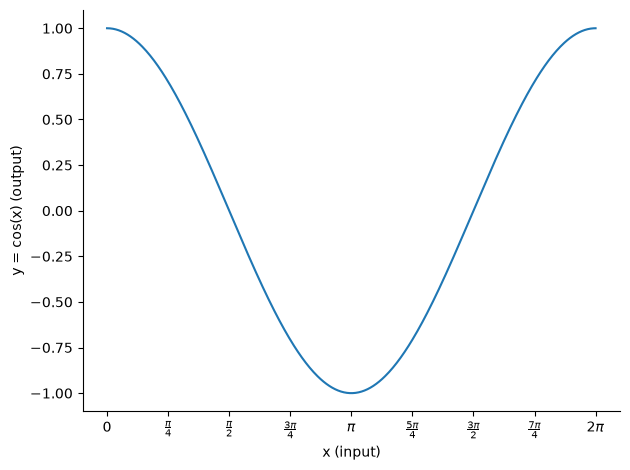

In [14]:
# plota a função cosseno no conjunto de treino
ax = plt.gca()

# define as marcações do eixo x a cada π/4 e as formata como frações de π
ax.xaxis.set_major_locator(MultipleLocator(np.pi/4)) 
ax.xaxis.set_major_formatter(FuncFormatter(pi_fraction_formatter))

ax.plot(x_train, y_train)
ax.set_xlabel("x (input)")
ax.set_ylabel("y = cos(x) (output)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# Função de ativação

In [15]:
my_act_function = ActivationFunction(my_activation_function)

# Treinamento

### Função de custo

O erro do modelo é avaliado pelo erro quadrático médio (*Mean Squared Error* — MSE):

$$
\mathrm{MSE} =
\frac{1}{N}\sum_{i=1}^{N}
\left(y_i-\hat{y}_i\right)^2,
$$

em que $N$ é o número de amostras, $y_i = \cos(x_i)$ é o valor desejado e $\hat{y}_i$ é a saída do modelo. Durante o treinamento, com AdamW, os pesos são atualizados para minimizar esse erro, com o decaimento dos pesos aplicado diretamente na atualização, de forma desacoplada do gradiente.

In [16]:
def train(optimizer, n_epochs=4500, seed=42):
    np.random.seed(seed) # fixa a semente para a inicialização dos pesos
    random.seed(seed) # fixa a semente para o embaralhamento das amostras

    # inicializa o modelo 
    p = Model(my_act_function, X_train.shape[1], 1, optimizer)

    idx = list(range(len(y_train))) # índices das amostras de treino
    mse_epoch = [] # armazena o erro quadrático médio por época

    for _ in range(n_epochs):
        shuffle(idx) # embaralha a ordem das amostras a cada época

        for k in idx:
            # calcula a saída estimada e atualiza os pesos com base no erro
            y_e = p.output(X_train[k])
            p.learn([y_train[k]], y_e, X_train[k])

        # calcula as previsões para todas as amostras de treino
        pred = X_train @ p.synaptic_weights[0]

        # MSE = média dos erros quadráticos na época
        mse_epoch.append(np.mean((y_train - pred)**2))
        
    return p, mse_epoch

### Otimizador AdamW

O AdamW adapta as atualizações dos parâmetros com base na média dos gradientes e na média dos quadrados dos gradientes, além de aplicar decaimento dos parâmetros (*weight decay*):

$$
\mathbf{g}_k = \nabla f(\mathbf{x}_{k-1})
$$

$$
\mathbf{m}_k =
\beta_1 \mathbf{m}_{k-1} + (1-\beta_1)\mathbf{g}_k
$$

$$
\mathbf{v}_k =
\beta_2 \mathbf{v}_{k-1} + (1-\beta_2)\mathbf{g}_k^2
$$

Os momentos são corrigidos:

$$
\hat{\mathbf{m}}_k =
\frac{\mathbf{m}_k}{1-\beta_1^k},
\qquad
\hat{\mathbf{v}}_k =
\frac{\mathbf{v}_k}{1-\beta_2^k}
$$

A atualização dos parâmetros é dada por:

$$
\mathbf{x}_k =
\mathbf{x}_{k-1}
-\eta\frac{\hat{\mathbf{m}}_k}
{\sqrt{\hat{\mathbf{v}}_k}+\varepsilon}
-\eta\lambda\mathbf{x}_{k-1}
$$

Em que $\eta$ é a taxa de aprendizagem, $\beta_1$ e $\beta_2$ são as taxas de decaimento exponencial dos momentos, $\hat{\mathbf{m}}_k$ e $\hat{\mathbf{v}}_k$ são os momentos corrigidos, $\varepsilon$ evita a divisão por zero e $\lambda$ controla o decaimento dos parâmetros.

In [17]:
p_adamw, mse_adamw = train(AdamW(eta=0.0001, lam=1e-4))

# Resultados

## Gráfico do erro por época

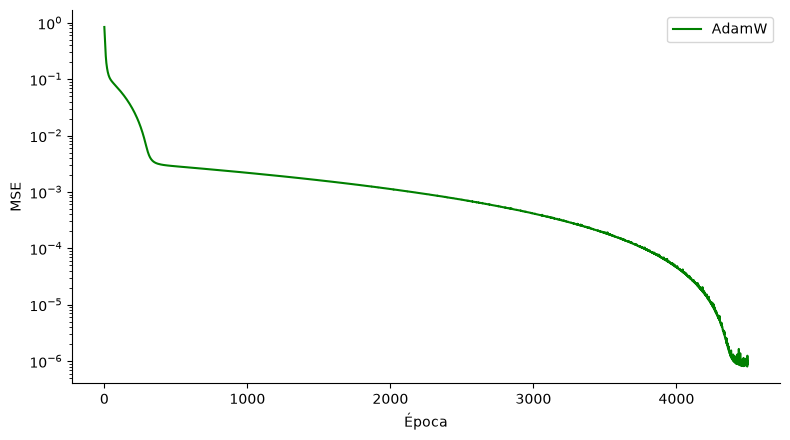

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(mse_adamw, color="green",label="AdamW")

ax.set_yscale("log")
ax.set_xlabel("Época")
ax.set_ylabel("MSE")
ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## Comparação da saída

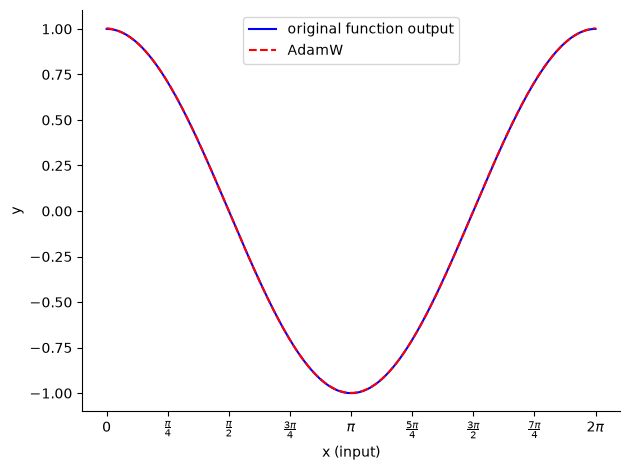

In [19]:
ax = plt.gca()

# define as marcações do eixo x a cada π/4 e as formata como frações de π
ax.xaxis.set_major_locator(MultipleLocator(np.pi/4))
ax.xaxis.set_major_formatter(FuncFormatter(pi_fraction_formatter))

ax.plot(x_train, y_train, color="blue", label = "original function output")

# plota as previsões do modelo treinado com AdamW
for name, p in [("AdamW", p_adamw)]:
    ax.plot(x_train, X_train @ p.synaptic_weights[0], "--", color="red", label=name)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlabel("x (input)")
ax.set_ylabel("y")
ax.legend()

plt.tight_layout()
plt.show()

# MSE no treino

In [20]:
# erro quadratico médio (MSE) no conjunto de treino
mse_train = np.mean((y_train - X_train @ p_adamw.synaptic_weights[0])**2)
print(f"MSE no conjunto de treino: {mse_train}")

MSE no conjunto de treino: 8.962855228128389e-07


## MSE no teste

In [21]:
# erro quadratico médio (MSE) no conjunto de teste
mse_test = np.mean((y_test - X_test @ p_adamw.synaptic_weights[0])**2)
print(f"MSE no conjunto de teste: {mse_test}")

MSE no conjunto de teste: 7.816640987559253e-07


#   Experimentos

## Experimento 1 ($\lambda = 10^{-2}$)

In [22]:
p_adamw2, mse_adamw2 = train(AdamW(eta=0.0001, lam=1e-2))

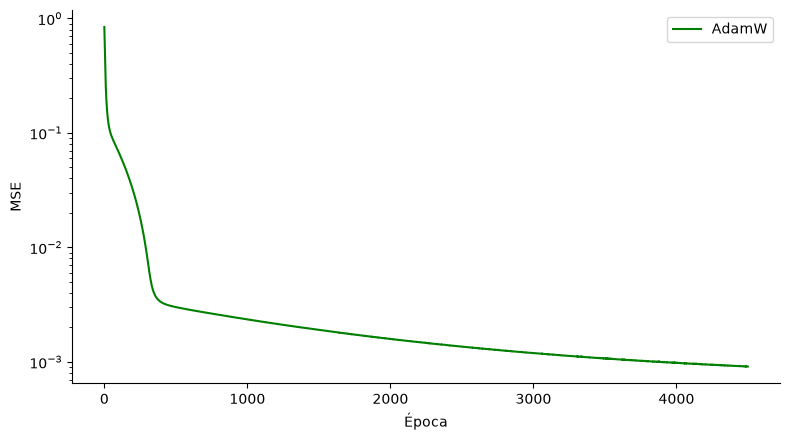

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(mse_adamw2, color="green",label="AdamW")

ax.set_yscale("log")
ax.set_xlabel("Época")
ax.set_ylabel("MSE")
ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

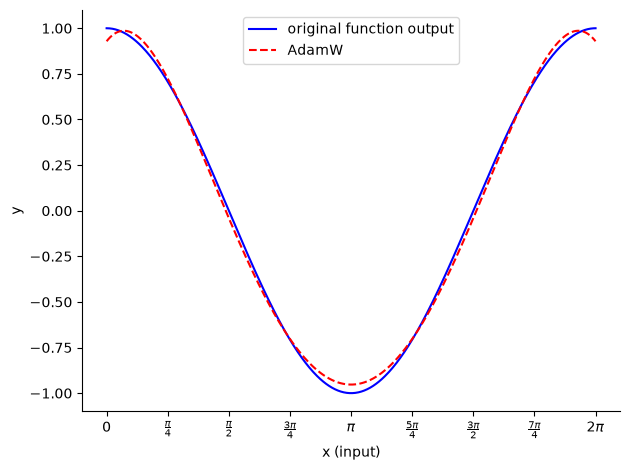

In [24]:
ax = plt.gca()

# define as marcações do eixo x a cada π/4 e as formata como frações de π
ax.xaxis.set_major_locator(MultipleLocator(np.pi/4))
ax.xaxis.set_major_formatter(FuncFormatter(pi_fraction_formatter))

ax.plot(x_train, y_train, color="blue", label = "original function output")

# plota as previsões do modelo treinado com AdamW
for name, p in [("AdamW", p_adamw2)]:
    ax.plot(x_train, X_train @ p.synaptic_weights[0], "--", color="red", label=name)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlabel("x (input)")
ax.set_ylabel("y")
ax.legend()

plt.tight_layout()
plt.show()

In [25]:
# erro quadratico médio (MSE) no conjunto de treino
mse_train = np.mean((y_train - X_train @ p_adamw2.synaptic_weights[0])**2)
print(f"MSE no conjunto de treino: {mse_train}")

MSE no conjunto de treino: 0.0009104571032886415


In [26]:
# erro quadratico médio (MSE) no conjunto de teste
mse_test = np.mean((y_test - X_test @ p_adamw2.synaptic_weights[0])**2)
print(f"MSE no conjunto de teste: {mse_test}")

MSE no conjunto de teste: 0.0008802364505109435


## Experimento 2 ($\lambda = 10^{-6}$)

In [27]:
p_adamw3, mse_adamw3 = train(AdamW(eta=0.0001, lam=1e-6))

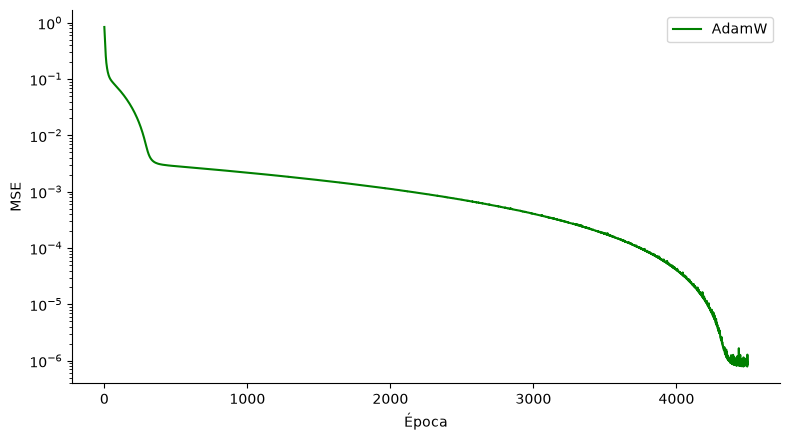

In [28]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(mse_adamw3, color="green",label="AdamW")

ax.set_yscale("log")
ax.set_xlabel("Época")
ax.set_ylabel("MSE")
ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

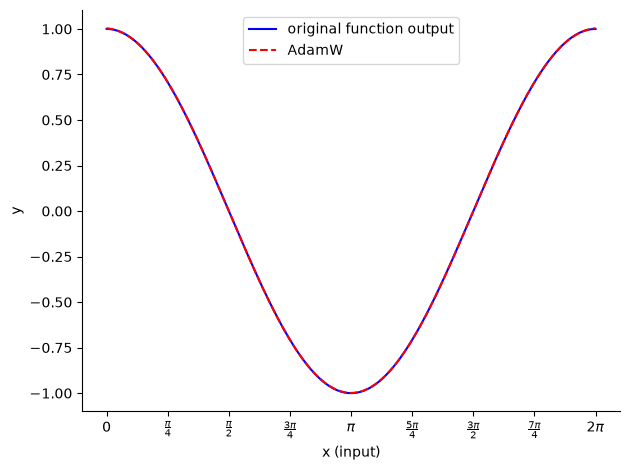

In [29]:
ax = plt.gca()

# define as marcações do eixo x a cada π/4 e as formata como frações de π
ax.xaxis.set_major_locator(MultipleLocator(np.pi/4))
ax.xaxis.set_major_formatter(FuncFormatter(pi_fraction_formatter))

ax.plot(x_train, y_train, color="blue", label = "original function output")

# plota as previsões do modelo treinado com AdamW
for name, p in [("AdamW", p_adamw3)]:
    ax.plot(x_train, X_train @ p.synaptic_weights[0], "--", color="red", label=name)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlabel("x (input)")
ax.set_ylabel("y")
ax.legend()

plt.tight_layout()
plt.show()

In [30]:
# erro quadratico médio (MSE) no conjunto de treino
mse_train = np.mean((y_train - X_train @ p_adamw3.synaptic_weights[0])**2)
print(f"MSE no conjunto de treino: {mse_train}")

MSE no conjunto de treino: 8.977066295848648e-07


In [31]:
# erro quadratico médio (MSE) no conjunto de teste
mse_test = np.mean((y_test - X_test @ p_adamw3.synaptic_weights[0])**2)
print(f"MSE no conjunto de teste: {mse_test}")

MSE no conjunto de teste: 7.623210323901264e-07


## Discussão

<div align="center">

| $\lambda$ | MSE de treino (final) | MSE de teste |
|:---:|:---:|:---:|
| $10^{-2}$ | $9{,}1046 \times 10^{-4}$ | $8{,}8024 \times 10^{-4}$ |
| $10^{-4}$ | $8{,}9629 \times 10^{-7}$ | $7{,}8166 \times 10^{-7}$ |
| $10^{-6}$ | $8{,}9771 \times 10^{-7}$ | $7{,}6232 \times 10^{-7}$ |

</div>

O AdamW apresentou MSE de $7{,}6232 \times 10^{-7}$ no conjunto de teste, o que indica uma aproximação muito precisa de $\cos(x)$ no intervalo considerado.

O decaimento dos pesos (*weight decay*) pode ajudar a reduzir o sobreajuste. Entretanto, neste experimento, com $\lambda = 10^{-4}$, praticamente não alterou a qualidade da aproximação no conjunto de teste. Nos experimentos com diferentes valores de $\lambda$, observou-se que o aumento desse parâmetro piorou a aproximação.

O aumento de $\lambda$ não trouxe benefícios significativos, pois o problema é relativamente simples e não apresenta indícios relevantes de sobreajuste. Assim, o decaimento dos pesos não se mostrou necessário e, quando muito intenso, prejudicou a aproximação da função.